## Author: Gabriel Vance
## Class: DSC630 - Predictive Analytics
## Professor: Professor Andrew Hua
## Date: September 23, 2025

# Purpose: This notebook performs the tasks outlined in 4.2 Assignment: Using Data to Improve MLB Attendance. Data from Dodgers 2022 season will be used and insights will be drawn to improve attendance.

Remove any data that is not relevant to the patient’s ALS condition.
Apply a standard scalar to the data.
Create a plot of the cluster silhouette score versus the number of clusters in a K-means cluster.
Use the plot created in (3) to choose an optimal number of clusters for K-means. Justify your choice.
Fit a K-means model to the data with the optimal number of clusters chosen in part (4).
Fit a PCA transformation with two features to the scaled data.
Make a scatterplot the PCA transformed data coloring each point by its cluster value.
Summarize your results and make a conclusion.

In [1]:
# Imports
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import f_oneway
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

# Ensure that all code cells are fully visible without scrolling
from IPython.core.display import display, HTML

display(HTML('''
<style>
div.CodeMirror pre {
    white-space: pre !important;
}
</style>
'''))

In [2]:
df = pd.read_csv('als_data.csv')

1. Remove any data that is not relevant to the patient’s ALS condition.


In [3]:
df = df.drop(['SubjectID', 'ID',], axis=1)

2. Apply a standard scalar to the data.

In [4]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

3. Create a plot of the cluster silhouette score versus the number of clusters in a K-means cluster.


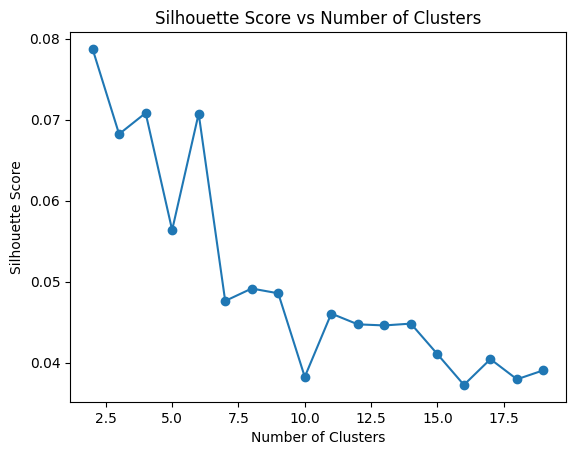

In [5]:
# Determine the optimal number of clusters using the silhouette score
silhouette_scores = []
cluster_range = range(2, 20)

# Evaluate silhouette score for each number of clusters
for n_clusters in cluster_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    cluster_labels = kmeans.fit_predict(scaled_data)
    score = silhouette_score(scaled_data, cluster_labels)
    silhouette_scores.append(score)

# Plot silhouette scores
plt.plot(cluster_range, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs Number of Clusters')
plt.show()

We can see that the largest silhouette score occurs at 2 clusters.

4. Use the plot created in (3) to choose an optimal number of clusters for K-means. Justify your choice.


In [6]:
# Get the max silhouette score and corresponding number of clusters
optimal_n_clusters = cluster_range[silhouette_scores.index(max(silhouette_scores))]
print(f"Optimal number of clusters chosen: {optimal_n_clusters}")

Optimal number of clusters chosen: 2


5. Fit a K-means model to the data with the optimal number of clusters chosen in part (4).


In [7]:
# Perform KMeans clustering with the optimal number of clusters
# As a reminder, KMeans is a clustering algorithm that partitions data into k clusters by minimizing the variance within each cluster.
kmeans = KMeans(n_clusters=optimal_n_clusters, random_state=42)
cluster_labels = kmeans.fit_predict(scaled_data)

6. Fit a PCA transformation with two features to the scaled data.


In [8]:
# PCA or Principal Component Analysis is a dimensionality reduction technique that transforms high-dimensional data into a lower-dimensional space while preserving as much variance as possible.
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

7. Make a scatterplot the PCA transformed data coloring each point by its cluster value.


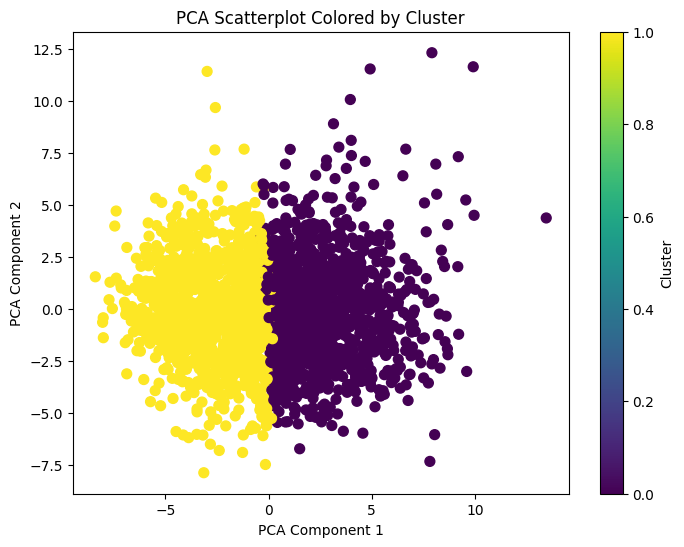

In [9]:
plt.figure(figsize=(8, 6))
plt.scatter(pca_data[:, 0], pca_data[:, 1], c=cluster_labels, cmap='viridis', s=50)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('PCA Scatterplot Colored by Cluster')
plt.colorbar(label='Cluster')
plt.show()

8. Summarize your results and make a conclusion.

The clustering analysis identified an optimal number of clusters using the silhouette score,
indicating distinct groupings within the ALS patient data. After scaling and dimensionality reduction
with PCA, the scatterplot showed clear separation between clusters, suggesting meaningful patterns.
These clusters may represent different ALS progression profiles or subgroups, which could be valuable
for further clinical investigation. Overall, the approach demonstrates that unsupervised learning
can reveal structure in ALS patient data, potentially aiding in personalized treatment strategies.

We're going to try dropping more columns to see if it improves clustering.

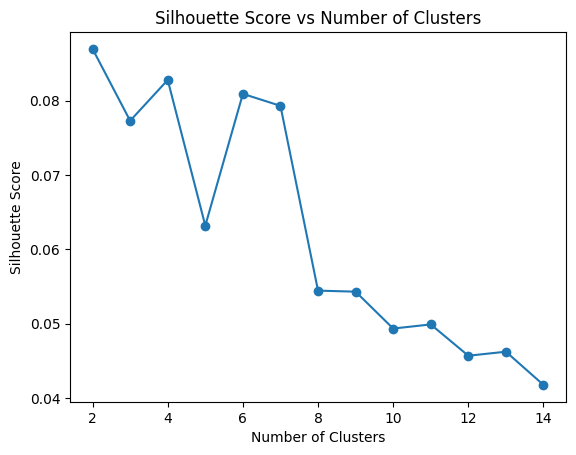

In [ ]:
# df_cleaned = df.drop(['trunk_max', 'trunk_median','trunk_min','trunk_range'], axis=1) # most optimal number was 2
# df_cleaned = df.drop(['trunk_max', 'trunk_median','trunk_min','trunk_range','pulse_max','pulse_median','pulse_min'], axis=1) # also was 2 
drop_cols = [
    "Age_mean",
    "Gender_mean",
    "bp_diastolic_max",
    "bp_diastolic_median",
    "bp_diastolic_min",
    "bp_diastolic_range",
    "bp_systolic_max",
    "bp_systolic_median",
    "bp_systolic_min",
    "bp_systolic_range",

] # This also set optimal number to 2 but the silo score was more much higher


df_cleaned = df.drop(drop_cols, axis=1)


scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_cleaned)


# Determine the optimal number of clusters using the silhouette score
silhouette_scores = []
cluster_range = range(2, 15)

# Evaluate silhouette score for each number of clusters
for n_clusters in cluster_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    cluster_labels = kmeans.fit_predict(scaled_data)
    score = silhouette_score(scaled_data, cluster_labels)
    silhouette_scores.append(score)

# Plot silhouette scores
plt.plot(cluster_range, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs Number of Clusters')
plt.show()